# Option pricing

*Beyond the scriptum — an application.*

---

An **option** is the right (not the obligation) to buy a share at a predetermined price $K$ at a
given time $T$. Whether you use it you only find out at the end: if the share costs more than $K$ you
buy cheaply and sell dear at once; if less, the right lapses. The payoff is therefore

$$\max(S_T - K,\ 0),$$

and the price of the option is the expectation of that payoff, discounted to today. Which is **exactly
a Monte Carlo problem** — the expectation of a function of a random variable.

This notebook is special in the repository for two reasons:

1. **It has an exact check.** For a European option there is the **Black–Scholes formula**, so we can
   verify the estimate to six significant digits.
2. **It is a problem where the variance reduction of exercise 7 finally really pays off.** For an
   Asian option a control variate gives an improvement on the order of **hundreds**, not percent.

You will see:

- a model of the share price and the Black–Scholes formula as a check
- **antithetic variables** on a European option
- the **Asian option**, where no formula exists — and a control variate that has one
- the **barrier option**, where the whole path matters

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def Phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def estimate(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    print(f"{name}: {mean:.6f} +- {se:.6f}  (exact {exact:.6f})")
    assert abs(mean - exact) <= k * se, name


# --- the market parameters ---
S0 = 100.0     # today's share price
K_ = 100.0     # the strike price of the option
R = 0.03       # the risk-free interest rate
SIGMA = 0.25   # the volatility
T = 1.0        # the time to maturity in years
STEPS = 50     # how many times we observe the path (for the Asian and the barrier option)

## 1. A model of the share price

The standard model (geometric Brownian motion) says that the **logarithm** of the price evolves as a
random walk with a drift:

$$S_T = S_0 \exp\!\Big( \big(r - \tfrac{\sigma^2}{2}\big)T + \sigma\sqrt{T}\,Z \Big), \qquad Z \sim N(0,1).$$

Why the logarithm: a price cannot be negative and the changes are **multiplicative** (a share falls by
10 %, not by 10 crowns). It is the first **multiplicative** process in the repository — everything
else was addition.

The price of the option is the discounted expectation of the payoff:

$$C = e^{-rT}\,E\big[\max(S_T - K, 0)\big].$$

For this case the integral can be computed by hand and gives the **Black–Scholes formula**

$$C = S_0\,\Phi(d_1) - K e^{-rT}\Phi(d_2), \qquad
d_1 = \frac{\ln(S_0/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}, \quad d_2 = d_1 - \sigma\sqrt{T}.$$

So we have a rare thing: a Monte Carlo problem where **we know the exact answer**.

Black–Scholes: 11.348477
Monte Carlo: 11.372051 +- 0.039986  (exact 11.348477)


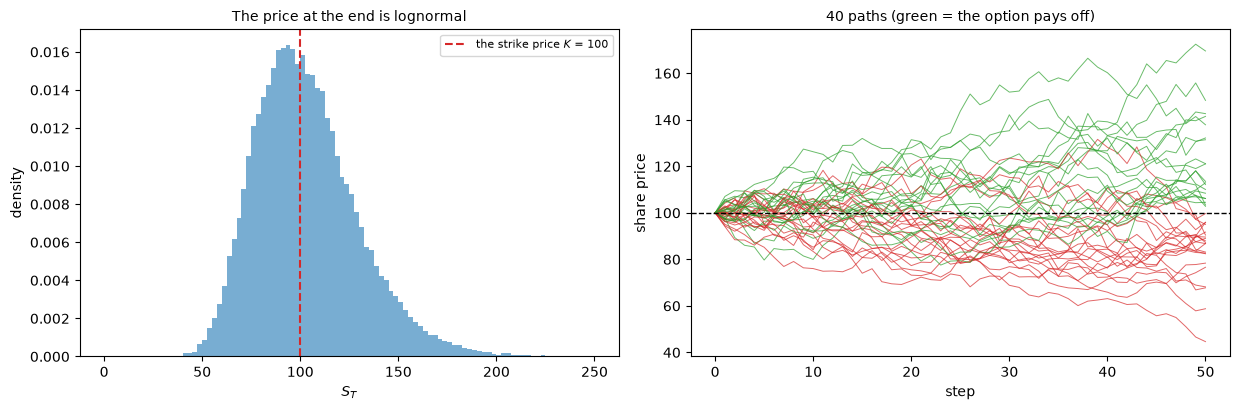

In [2]:
def black_scholes(S0, K, r, sig, T):
    '''The exact price of a European call option.'''
    d1 = (math.log(S0 / K) + (r + sig * sig / 2) * T) / (sig * math.sqrt(T))
    d2 = d1 - sig * math.sqrt(T)
    return S0 * Phi(d1) - K * math.exp(-r * T) * Phi(d2)


def price_at_end(z=None):
    '''S_T from a single normal number.'''
    z = random.gauss(0, 1) if z is None else z
    return S0 * math.exp((R - SIGMA**2 / 2) * T + SIGMA * math.sqrt(T) * z)


EXACT = black_scholes(S0, K_, R, SIGMA, T)
print(f"Black–Scholes: {EXACT:.6f}")

n = 200_000
payoffs = [math.exp(-R * T) * max(price_at_end() - K_, 0.0) for _ in range(n)]
check("Monte Carlo", *estimate(payoffs), EXACT)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
ends = [price_at_end() for _ in range(50_000)]
w = 250 / 100
ax.hist(ends, bins=100, range=(0, 250), weights=[1 / (len(ends) * w)] * len(ends), alpha=0.6)
ax.axvline(K_, color="tab:red", ls="--", label=f"the strike price $K$ = {K_:.0f}")
ax.set_xlabel("$S_T$")
ax.set_ylabel("density")
ax.set_title("The price at the end is lognormal", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
for _ in range(40):
    dt = T / STEPS
    S, path = S0, [S0]
    for _ in range(STEPS):
        S *= math.exp((R - SIGMA**2 / 2) * dt + SIGMA * math.sqrt(dt) * random.gauss(0, 1))
        path.append(S)
    ax.plot(path, lw=0.7, alpha=0.7, color="tab:green" if path[-1] > K_ else "tab:red")
ax.axhline(K_, color="k", ls="--", lw=1)
ax.set_xlabel("step")
ax.set_ylabel("share price")
ax.set_title("40 paths (green = the option pays off)", fontsize=10)
plt.tight_layout()
plt.show()

## 2. Antithetic variables

The payoff $\max(S_T - K, 0)$ is an **increasing** function of the normal number $Z$. That is exactly
the situation in which, by exercise 7, **antithetic variables** help: instead of two independent $Z$
we use the pair $(Z, -Z)$, which is negatively correlated.

In [3]:
def european_antithetic(n_pairs):
    values = []
    for _ in range(n_pairs):
        z = random.gauss(0, 1)
        a = math.exp(-R * T) * max(price_at_end(z) - K_, 0.0)
        b = math.exp(-R * T) * max(price_at_end(-z) - K_, 0.0)
        values.append((a + b) / 2)
    return values


N = 100_000
plain = [math.exp(-R * T) * max(price_at_end() - K_, 0.0) for _ in range(2 * N)]
anti = european_antithetic(N)          # the same number of evaluations!

m1, se1 = estimate(plain)
m2, se2 = estimate(anti)
se2 = se2 / math.sqrt(1)                # anti has N pairs = 2N evaluations
print(f"{'method':>24s} {'estimate':>11s} {'std error':>11s}")
print(f"{'plain MC':>24s} {m1:>11.6f} {se1:>11.6f}")
print(f"{'antithetic':>24s} {m2:>11.6f} {se2:>11.6f}")
print(f"{'exact':>24s} {EXACT:>11.6f}")
print(f"\ngain: {(se1 / se2) ** 2:.1f}x smaller variance at the same number of evaluations")
assert abs(m2 - EXACT) < 5 * se2

                  method    estimate   std error
                plain MC   11.281107    0.039854
              antithetic   11.375838    0.030998
                   exact   11.348477

gain: 1.7x smaller variance at the same number of evaluations


## 3. The Asian option: when no formula exists

An **Asian option** does not pay according to the final price but according to the **average** price
over the whole period:

$$\max\!\left(\frac{1}{n}\sum_{i=1}^{n} S_{t_i} - K,\ 0\right).$$

It is used because it is harder to manipulate — moving the price on a single day is not enough.

For the arithmetic average of lognormal variables **no closed formula exists** (a sum of lognormals is
not lognormal). Monte Carlo, however, works in exactly the same way.

### A control variate that has a formula

And now the trick. If we replace the arithmetic average by the **geometric** one,

$$G = \Big(\prod_i S_{t_i}\Big)^{1/n} = \exp\!\Big(\tfrac1n \textstyle\sum_i \ln S_{t_i}\Big),$$

then $\ln G$ is a sum of normal variables, hence **normal** — and the price of such an option can be
computed. At the same time the geometric Asian option is almost perfectly correlated with the
arithmetic one.

That is exactly the control variate from exercise 7: a variable close to ours whose expectation we
know exactly.

Specifically, $\ln G \sim N(\mu_G, \sigma_G)$ with

$$\mu_G = \ln S_0 + \Big(r - \tfrac{\sigma^2}{2}\Big)\frac{T(n+1)}{2n}, \qquad
\sigma_G^2 = \sigma^2 T\,\frac{(n+1)(2n+1)}{6n^2},$$

and the price comes out of the formula for a lognormal variable.

In [4]:
def geometric_asian_exact(S0, K, r, sig, T, n):
    '''The exact price of a geometric Asian option.'''
    mu_G = math.log(S0) + (r - sig * sig / 2) * T * (n + 1) / (2 * n)
    var_G = sig * sig * T * (n + 1) * (2 * n + 1) / (6 * n * n)
    sd_G = math.sqrt(var_G)
    d1 = (mu_G - math.log(K) + var_G) / sd_G
    d2 = d1 - sd_G
    return math.exp(-r * T) * (math.exp(mu_G + var_G / 2) * Phi(d1) - K * Phi(d2))


def path_stats():
    '''One path; returns (arithmetic average, geometric average, minimum).'''
    dt = T / STEPS
    S, total, total_log, minimum = S0, 0.0, 0.0, S0
    for _ in range(STEPS):
        S *= math.exp((R - SIGMA**2 / 2) * dt + SIGMA * math.sqrt(dt) * random.gauss(0, 1))
        total += S
        total_log += math.log(S)
        minimum = min(minimum, S)
    return total / STEPS, math.exp(total_log / STEPS), minimum


G_EXACT = geometric_asian_exact(S0, K_, R, SIGMA, T, STEPS)
print(f"the geometric Asian option, the exact formula: {G_EXACT:.6f}")

n = 100_000
ar, ge = [], []
for _ in range(n):
    a, g, _ = path_stats()
    ar.append(math.exp(-R * T) * max(a - K_, 0.0))
    ge.append(math.exp(-R * T) * max(g - K_, 0.0))

check("the geometric Asian, MC", *estimate(ge), G_EXACT)   # a check of the formula by simulation

m_ar, se_ar = estimate(ar)
print(f"\nthe arithmetic Asian, plain MC: {m_ar:.6f} +- {se_ar:.6f}")

# the control variate
m_g = sum(ge) / n
cov = sum((x - m_ar) * (y - m_g) for x, y in zip(ar, ge)) / (n - 1)
var_g = sum((y - m_g) ** 2 for y in ge) / (n - 1)
c_opt = cov / var_g
correlation = cov / math.sqrt(var_g * sum((x - m_ar) ** 2 for x in ar) / (n - 1))
adjusted = [x - c_opt * (y - G_EXACT) for x, y in zip(ar, ge)]
m_cv, se_cv = estimate(adjusted)
print(f"the arithmetic Asian, control:  {m_cv:.6f} +- {se_cv:.6f}")
print(f"\ncorrelation of the arithmetic and the geometric: {correlation:.5f}   (optimal c = {c_opt:.3f})")
print(f"gain: {(se_ar / se_cv) ** 2:.0f}x smaller variance")
print(f"so plain MC would need {(se_ar / se_cv) ** 2:.0f}x more paths for the same accuracy")

the geometric Asian option, the exact formula: 6.201223


the geometric Asian, MC: 6.224032 +- 0.029999  (exact 6.201223)

the arithmetic Asian, plain MC: 6.524525 +- 0.031302
the arithmetic Asian, control:  6.500739 +- 0.001064

correlation of the arithmetic and the geometric: 0.99942   (optimal c = 1.043)
gain: 865x smaller variance
so plain MC would need 865x more paths for the same accuracy


The correlation between the arithmetic and the geometric version is over 0.999, and the gain is
therefore on the order of hundreds. This is the strongest demonstration of a control variate in the
whole repository — in exercise 7 we got roughly 66x on an artificial example, here it comes out at
**several hundred**.

The reason is general and worth remembering: **a good control variate is the same problem, just a
little simpler.** You do not look for a similar function, you look for a simplification that still has
a formula.

## 4. The barrier option: the whole path matters

The last variant: an option that **lapses** if the share price ever falls below a barrier $B$ during
its life (down-and-out). The payoff is

$$\max(S_T - K, 0)\cdot \mathbf 1\big[\min_t S_t > B\big].$$

Here the simulation of paths shows the main point: it is not about the distribution of the final price
but about the **whole trajectory**. An analytic formula exists, but only for continuous monitoring —
we monitor at $n$ moments, which gives a different (and for real contracts more realistic) price.

  barrier B           option price   share of the no-barrier price


          0       11.38397 +- 0.06377                         100.3%


         60       11.47504 +- 0.06411                         101.1%


         70       11.25821 +- 0.06289                          99.2%


         80       11.08753 +- 0.06332                          97.7%


         90        9.14189 +- 0.06186                          80.6%


         95        6.43636 +- 0.05583                          56.7%

B = 0 means no barrier, so Black–Scholes (11.3485) has to come out — and it does.


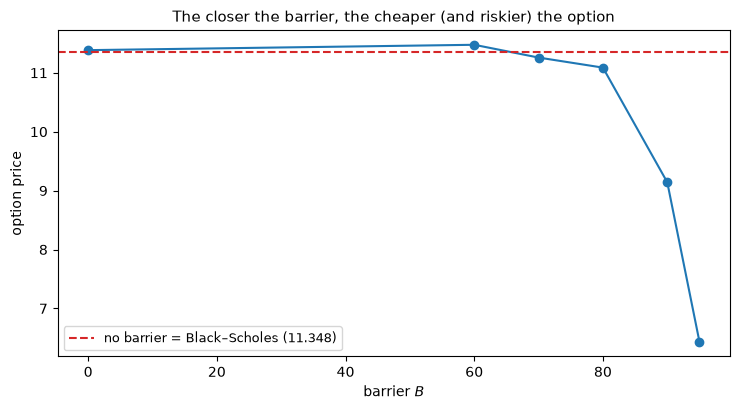

In [5]:
def path_with_end():
    dt = T / STEPS
    S, minimum = S0, S0
    for _ in range(STEPS):
        S *= math.exp((R - SIGMA**2 / 2) * dt + SIGMA * math.sqrt(dt) * random.gauss(0, 1))
        minimum = min(minimum, S)
    return S, minimum


print(f"{'barrier B':>11s} {'option price':>22s} {'share of the no-barrier price':>31s}")
barriers = (0, 60, 70, 80, 90, 95)
prices = []
for B in barriers:
    vals = []
    for _ in range(80_000):
        ST, mn = path_with_end()
        vals.append(math.exp(-R * T) * max(ST - K_, 0.0) if mn > B else 0.0)
    m, se = estimate(vals)
    prices.append(m)
    print(f"{B:>11d} {m:>14.5f} +- {se:.5f} {m / EXACT:>30.1%}")

print(f"\nB = 0 means no barrier, so Black–Scholes ({EXACT:.4f}) has to come out — and it does.")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(barriers, prices, "o-")
ax.axhline(EXACT, color="tab:red", ls="--", label=f"no barrier = Black–Scholes ({EXACT:.3f})")
ax.set_xlabel("barrier $B$")
ax.set_ylabel("option price")
ax.set_title("The closer the barrier, the cheaper (and riskier) the option", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Summary

| Concept | What to remember |
|---------|------------------|
| The option price | $e^{-rT}E[\text{payoff}]$ — an expectation, hence a problem for MC |
| The price model | multiplicative: $S_T = S_0 e^{(r-\sigma^2/2)T + \sigma\sqrt T Z}$ |
| Black–Scholes | the exact price of a European option — a rare chance to verify MC to 6 digits |
| Antithetic | the payoff is monotone in $Z$, so the pair $(Z, -Z)$ helps |
| The Asian option | the average instead of the end; **the arithmetic has no formula**, the geometric does |
| The control variate | the geometric Asian: correlation > 0.999 ⟹ a gain in the hundreds |
| The barrier option | the whole path decides, not just the end; $B = 0$ returns Black–Scholes |

The main idea: **the best control variate is a simplified version of the same problem.** Do not look
for a similar function — look for what in the problem can be simplified so that it can still be
computed exactly.

### Try it yourself

1. Price a **put** option (payoff $\max(K - S_T, 0)$) and verify the parity $C - P = S_0 - Ke^{-rT}$.
2. Add antithetic sampling to the control variate as well. Do the gains multiply, or do they overlap?
3. How does the gain from the control variate depend on the number of steps $n$? Try $n = 5$ and
   $n = 500$.
4. Compute the option's **delta** (the derivative of the price with respect to $S_0$) by a finite
   difference. Why do you have to use **the same** random numbers for both prices? (Hint: common random
   numbers are another variance-reduction method.)
5. The barrier option is monitored only at $n$ moments. How does the price change as $n$ grows? What
   does it converge to?
6. Replace the normal distribution of returns by a heavier tail (a Student's, say). By how much does
   the price of an option deep out of the money change?